# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [ ]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

model = CensoredNormalMLE(y_train, X_train, train["event"])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

## Part 1

In [24]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/metabric.csv')

In [25]:
df['Overall Survival Status'].value_counts()

Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64

<Axes: xlabel='Overall Survival (Months)', ylabel='Density'>

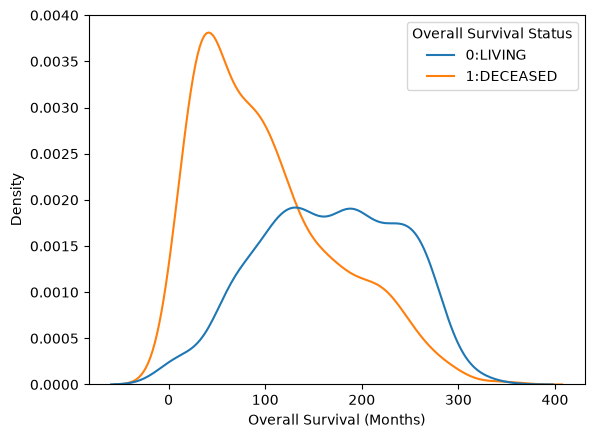

In [26]:
import seaborn as sns

df = df[df['Tumor Stage']!=0]
sns.kdeplot(data=df, x='Overall Survival (Months)', hue='Overall Survival Status')

## Part 2

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

numeric = ['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count', 'Tumor Size']
cat = ['Chemotherapy', 'Hormone Therapy', 'Radio Therapy', 'Tumor Stage']

X = df[numeric+cat]
y = np.log(df['Overall Survival (Months)'])
event = (df['Overall Survival Status']=='1:DECEASED').astype(int)

X_train, X_test, y_train, y_test, event_train, event_test = train_test_split(
    X, y, event, test_size=0.2, random_state=42, stratify=event
)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
])

pipe = Pipeline([
    ("preprocess", preprocess),
    ("regressor", LinearRegression()),
])

pipe.fit(X_train, y_train)
y_pred_method1 = pipe.predict(X_test)

r2 = r2_score(y_test, y_pred_method1)
rmse = mean_squared_error(y_test, y_pred_method1) ** 0.5

print("R2:", round(r2, 3))
print("RMSE:", round(rmse, 3))

R2: 0.126
RMSE: 0.741


In [28]:
from sklearn.base import clone
pipe_2 = clone(pipe)
dead = event_train == 1
pipe_2.fit(X_train[dead], y_train[dead])
y_pred_method2 = pipe_2.predict(X_test)
r2 = r2_score(y_test, y_pred_method2)
rmse = mean_squared_error(y_test, y_pred_method2) ** 0.5

print("R2:", round(r2, 3))
print("RMSE:", round(rmse, 3))

R2: -0.021
RMSE: 0.801


**Method 1 is inaccurate imputation because the overall survival column cannot possibly contain death data about the people who are still living. So their overall survival gets estimated to the time of the study, which is not accurate. This was not an actual observed value, it is technically made up.**

**Method 2 simply removes any living patients, which is serious data loss, so any models or resulst from that data is not representative of the overall picture. It will be favored towards the patients in the study that did not survive. Method 2 is biased towards the patients that passed away.**

## Part 3

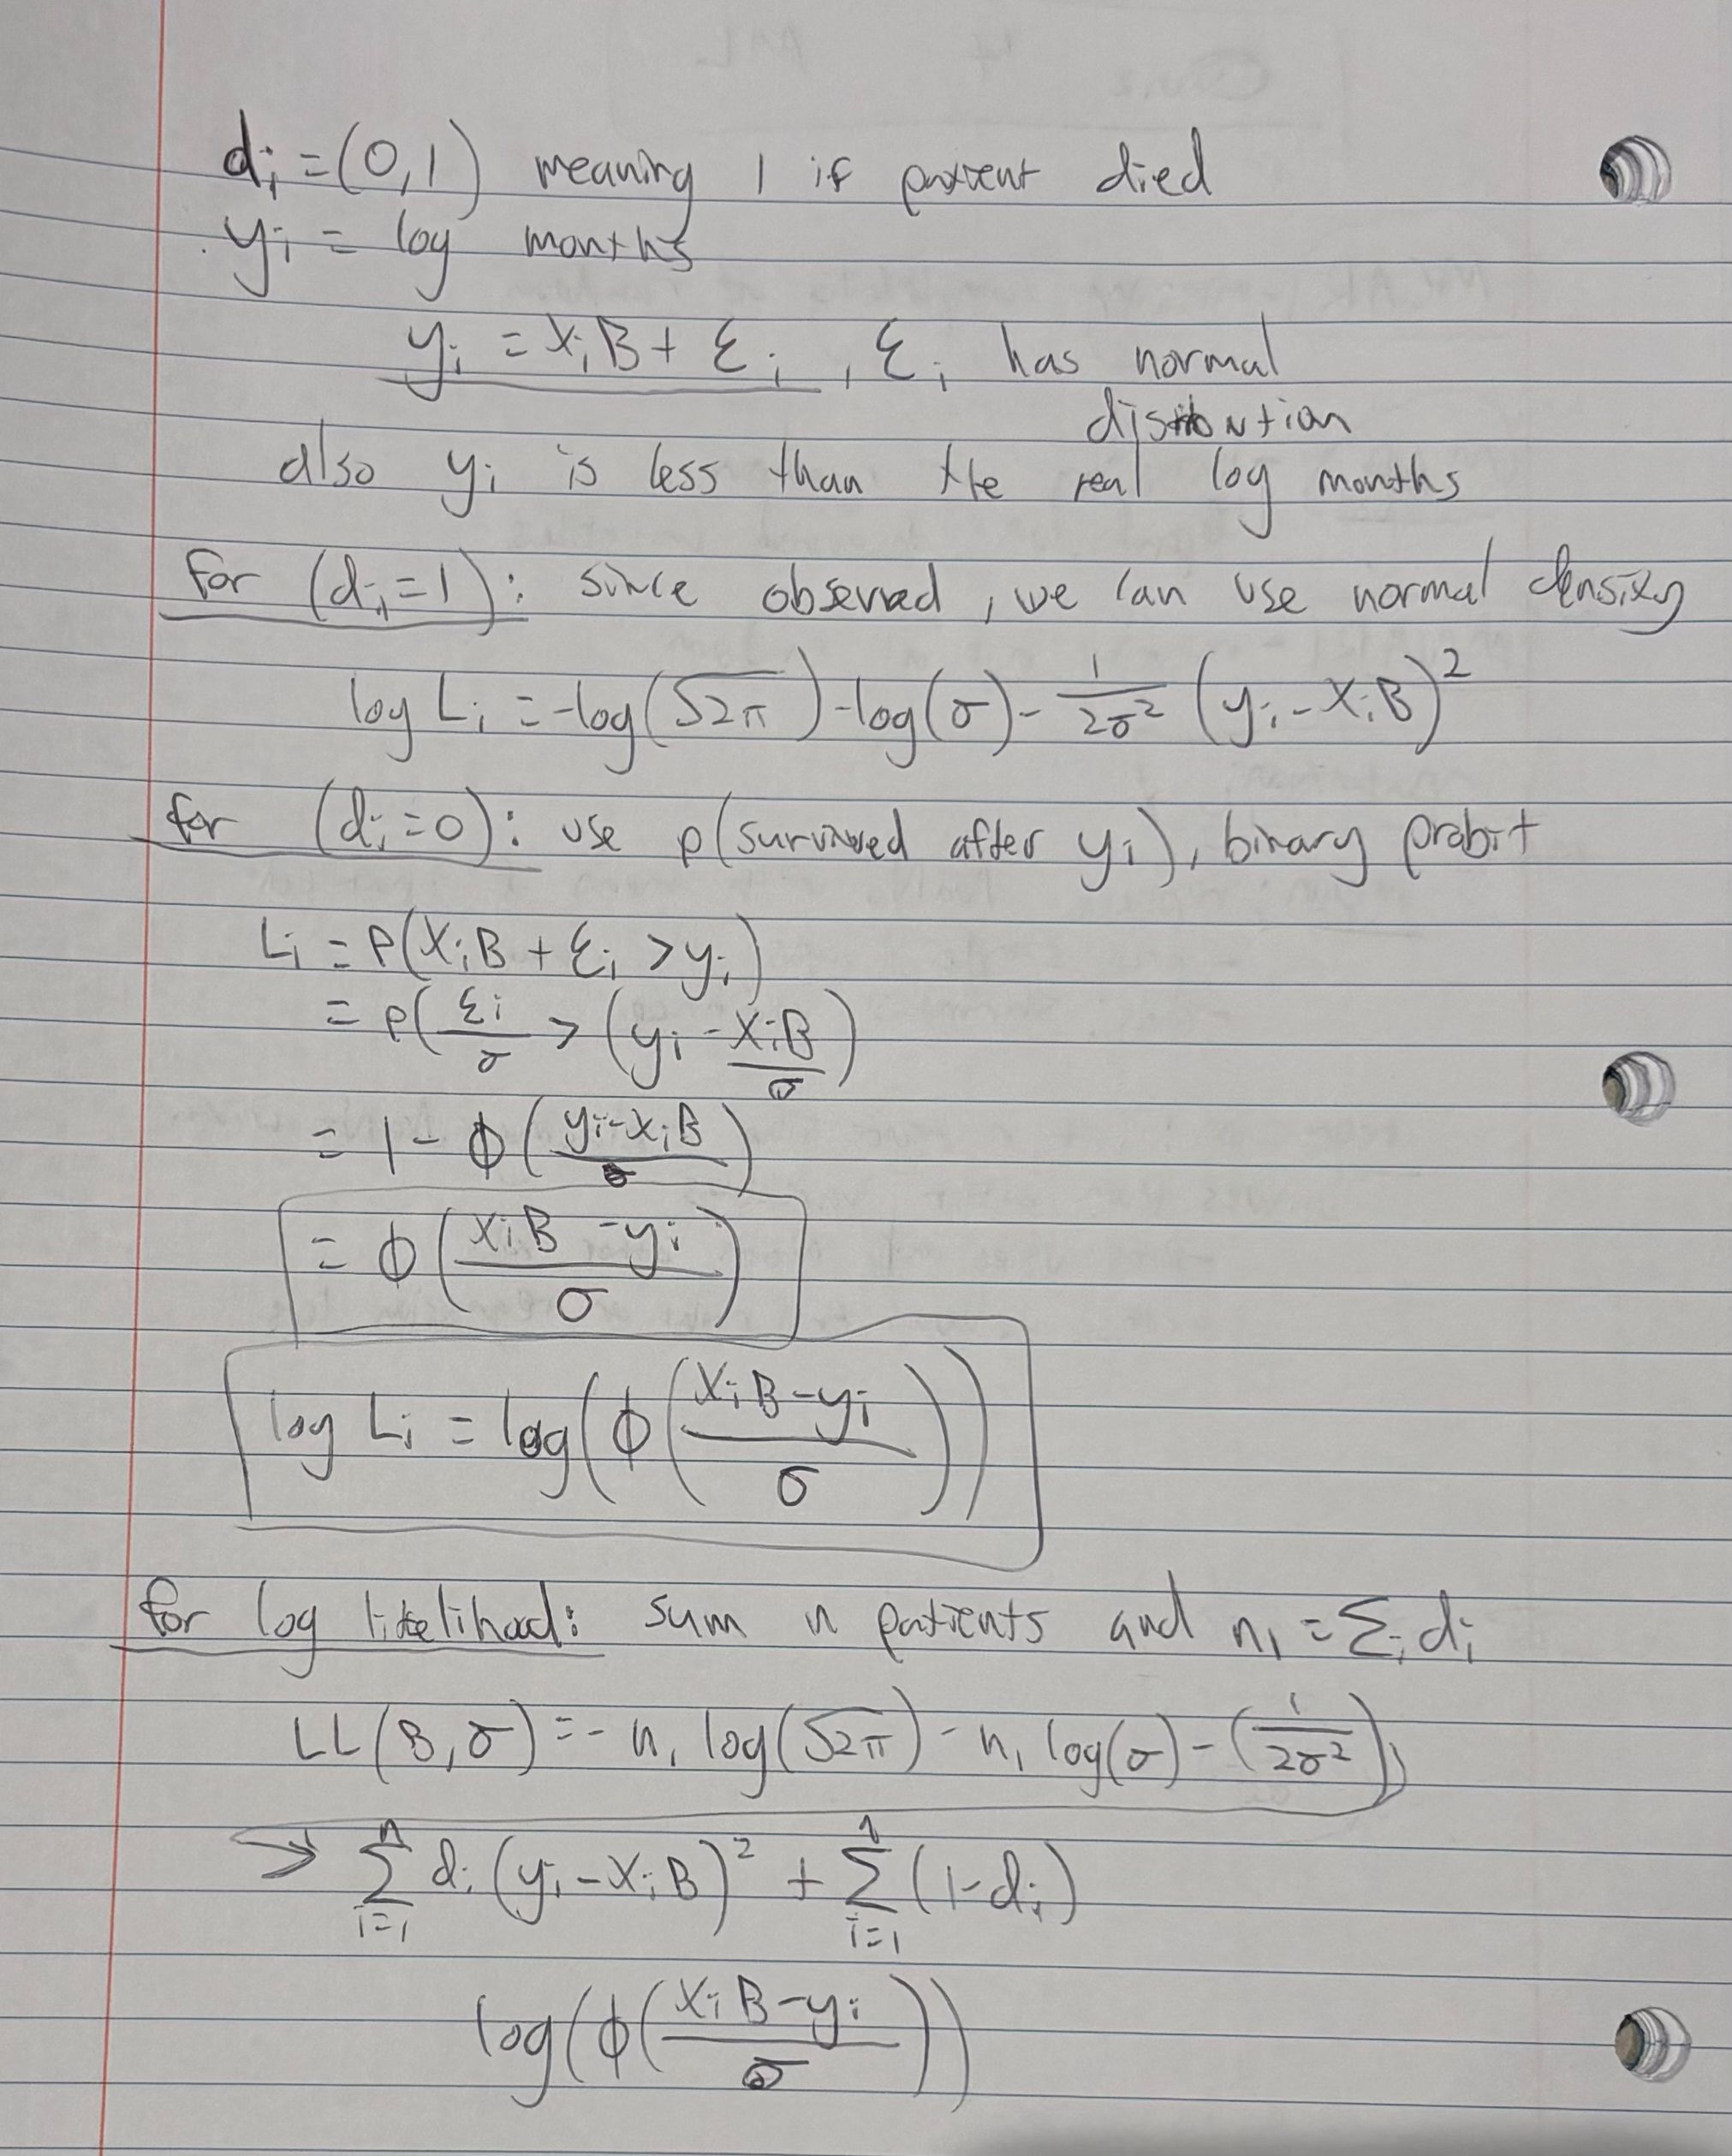

## Part 4

In [22]:
import statsmodels.api as sm
from statsmodels.base.model import GenericLikelihoodModel
from scipy.stats import norm

In [33]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

prep = pipe['preprocess']
names = prep.get_feature_names_out()

X_train_4 = prep.transform(X_train)
X_test_4 = prep.transform(X_test)

X_train_4 = pd.DataFrame(X_train_4, columns=names, index=X_train.index)
X_test_4 = pd.DataFrame(X_test_4, columns=names, index=X_test.index)

X_train_mle = sm.add_constant(X_train_4)
X_test_mle = sm.add_constant(X_test_4, has_constant='add')

train_pred = pipe.predict(X_train)
diff = y_train-train_pred

start = np.r_[pipe['regressor'].intercept_, pipe['regressor'].coef_, np.log(diff.std())]

model = CensoredNormalMLE(y_train, X_train_mle, event_train)
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                              CensoredNormalMLE Results                              
Dep. Variable:     Overall Survival (Months)   Log-Likelihood:                -1183.6
Model:                     CensoredNormalMLE   AIC:                             2391.
Method:                   Maximum Likelihood   BIC:                             2451.
Date:                       Wed, 18 Nov 2026                                         
Time:                               19:59:43                                         
No. Observations:                       1072                                         
Df Residuals:                           1060                                         
Df Model:                                 10                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
cons

In [36]:
print("Method 1 coefficients:")
print(f"Intercept: {pipe['regressor'].intercept_:.3f}")
print(pd.Series(pipe['regressor'].coef_, index=names).round(3))

print("Method 2 coefficients:")
print(f"Intercept: {pipe_2['regressor'].intercept_:.3f}")
print(pd.Series(pipe_2['regressor'].coef_, index=names).round(3))

Method 1 coefficients:
Intercept: 4.687
num__Age at Diagnosis                -0.136
num__Lymph nodes examined positive   -0.139
num__Mutation Count                   0.013
num__Tumor Size                      -0.048
cat__Chemotherapy_YES                -0.210
cat__Hormone Therapy_YES              0.058
cat__Radio Therapy_YES                0.073
cat__Tumor Stage_2.0                 -0.223
cat__Tumor Stage_3.0                 -0.325
cat__Tumor Stage_4.0                 -0.724
dtype: float64
Method 2 coefficients:
Intercept: 4.417
num__Age at Diagnosis                -0.043
num__Lymph nodes examined positive   -0.139
num__Mutation Count                   0.033
num__Tumor Size                      -0.029
cat__Chemotherapy_YES                -0.327
cat__Hormone Therapy_YES              0.235
cat__Radio Therapy_YES                0.008
cat__Tumor Stage_2.0                 -0.236
cat__Tumor Stage_3.0                 -0.436
cat__Tumor Stage_4.0                 -0.961
dtype: float64


## Part 5

**The censored MLE generally increased the absolute values of coefficients from methods 1 and 2. For example, the coefficient for age in the censored MLE is -0.32, while it is -0.13 and -0.04 for methods 1 and 2. Another noticeable difference is tumor size (-0.1 for MLE, -0.04 for method 1, -0.03 for method 2). The censored MLE has the highest intercept of 5.05, (4.6 for method 1 and 4.4 for method 2). Almost every absval(coefficient) for the MLE was larger. The above occurs because the 2 initial models cannot train or test on survival times outside of the logged window, so shorter survival overall is predicted when compared to the MLE. Effects are shrunk towards 0, which is why the absval of the coefs increased.**


In [39]:
beta = mle.params[:-1]
y_pred_mle = np.dot(X_test_mle, beta)

results = X_test[['Tumor Stage']].copy()
results['Method 1'] = y_pred_method1
results['Method 2'] = y_pred_method2
results['MLE'] = y_pred_mle
results['died'] = event_test

cols = ['Method 1', 'Method 2', 'MLE', 'died']

print("Mean prediction by tumor stage:")
print(results.groupby('Tumor Stage')[cols].mean().round(2))

Mean prediction by tumor stage:
             Method 1  Method 2   MLE  died
Tumor Stage                                
1.0              4.85      4.61  5.43  0.49
2.0              4.44      4.25  4.86  0.60
3.0              4.13      3.80  4.36  0.70
4.0              3.56      3.22  3.58  1.00



**Comparing the predictions on the test set, we see that methods 1 and 2 predict shorter survival time in general than the MLE does. Also, method 2 generally predicted the shortest, as the suriviving patients were just removed. The most noticeable difference is for patients in tumor stage 1, as these are the patients likely to survive for longer (4.85 for method 1, 4.61 for method 2, 5.43 for MLE). The first 2 methods are simply unable to properly handle surviving patients. Clearly patients in low tumor stages receive systematically biased predictions by models 1 and 2. The prediction difference is the smallest for tumor stage 4.**

